# Manual

## Importer les bibliothèque

In [ ]:
import kagglehub
from pathlib import Path
import numpy as np
from PIL import Image
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img

## Charger le dataset

In [2]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
path = Path(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


## Explorer la structure

In [ ]:


train_dir =  path / "chest_xray" / "chest_xray" / "train"

val_dir =  path / "chest_xray" / "chest_xray" / "val"

test_dir =  path / "chest_xray" / "chest_xray" / "test"


train_classes_paths = [train_dir / "NORMAL", train_dir / "PNEUMONIA"]
val_classes_paths = [val_dir / "NORMAL", val_dir / "PNEUMONIA"]
test_classes_paths = [test_dir / "NORMAL", test_dir / "PNEUMONIA"]




## Vérifier le nombre d'images & la répartition des images

In [ ]:
  
allowed_ext = (".jpeg", ".png", ".jpg")
def get_images(images_dir: list, type_index):
    return [
        i for i in images_dir[type_index].rglob("*")
        if i.name.endswith(allowed_ext)
    ]

In [5]:
def charts(count: dict):
    classes = ("NORMAL", "PNEUMONIA")
    fig, axes = plt.subplots(1, 3,  figsize=(12, 5),)
    
    for key, value in count.items():
        i = list(count.keys()).index(key)
        axes[i].bar(classes, value)
        axes[i].set_title(key)
        axes[i].set_xlabel("classes")
        axes[i].set_ylabel(f"{key} count")
    
    plt.tight_layout()
    plt.show()
    

In [6]:

# TRAIN


train_image = {
    "normal": get_images(train_classes_paths, 0),
    "pneumonia": get_images(train_classes_paths, 1)
}

val_image = {
    "normal": get_images(val_classes_paths, 0),
    "pneumonia": get_images(val_classes_paths, 1)
}

test_image = {
    "normal": get_images(test_classes_paths, 0),
    "pneumonia": get_images(test_classes_paths, 1)
}


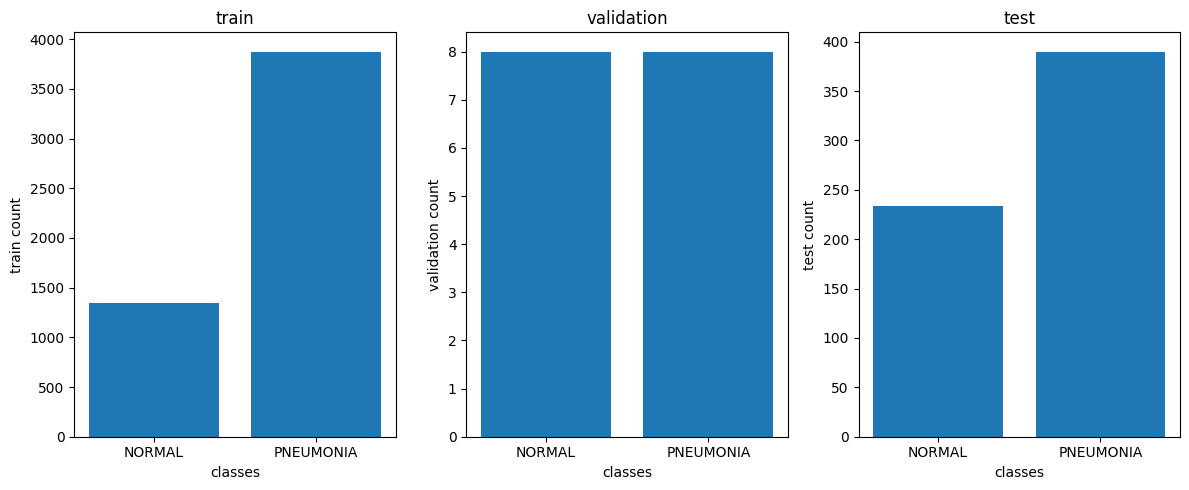

In [7]:

countes =  {
    "train": [len(train_image["normal"]), len(train_image["pneumonia"])],
    "validation": [len(val_image["normal"]), len(val_image["pneumonia"])],
    "test": [len(test_image["normal"]), len(test_image["pneumonia"])]
}

charts(countes)

## Identifier les éventuels problèmes

In [ ]:
def check_image(img_path):
    try:
        with Image.open(img_path) as img:
            img.verify()
            img.convert()
            return True 
    except:
        return False

In [9]:

train_valid = train_image
# {
#     cls: [img for img in train_image[cls] if check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }

val_valid = val_image
# {
#     cls: [img for img in val_image[cls] if check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }

test_valid =  test_image
# {
#     cls: [img for img in test_image[cls] if check_image(img)]
#     for cls in ["normal", "pneumonia"]
# }



## Redimensionner les images et convertir au format RGB

In [ ]:

from tensorflow.keras.utils import img_to_array





def process_image(img):
    image = load_img(
        img,
        target_size=(180, 180),
        color_mode="rgb"
    )
    # if normalize:
    image = img_to_array(image) / 255.0
    image = np.asarray(image, dtype=np.float32)
    
    # else:    
    #     image = img_to_array(image)
    return image
    

In [11]:
train_processed = {
    cls: np.array([
        process_image(path)
        for path in train_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

val_processed = {
    cls: np.array([
        process_image(path)
        for path in val_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

test_processed = {
    cls: np.array([
        process_image(path)
        for path in test_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

## Préparer les images au format attendu par le modèle CNN

In [ ]:

# from tensorflow.keras.utils import img_to_array

# train_processed = {
#     cls: np.array([
#         img_to_array(path)
#         for path in train_redim[cls]
#     ], dtype=np.float32)
#     for cls in ["normal", "pneumonia"]
# }


# val_processed = {
#     cls: np.array([
#         img_to_array(path)
#         for path in val_redim[cls]
#     ], dtype=np.float32)
#     for cls in ["normal", "pneumonia"]
# }

# test_processed = {
#     cls: np.array([
#         img_to_array(path)
#         for path in test_redim[cls]
#     ], dtype=np.float32)
#     for cls in ["normal", "pneumonia"]
# }

## Associer les labels aux images

In [13]:
# Train
X_train = np.concatenate(
    (
        train_processed["normal"],
        train_processed["pneumonia"]
    ),
    axis=0
)
y_train = np.concatenate(
    (
        np.zeros(len(train_processed["normal"])),
        np.ones(len( train_processed["pneumonia"]))
    ),
    axis= 0
)

# Validation
X_val = np.concatenate(
    (
        val_processed["normal"], 
        val_processed["pneumonia"]
    ), 
    axis=0
)
y_val = np.concatenate(
    (
        np.zeros(len(val_processed["normal"])),
        np.ones(len( val_processed["pneumonia"]))
    ),
    axis= 0
)
# Test
X_test = np.concatenate(
    (
        test_processed["normal"], 
        test_processed["pneumonia"]
    ), 
    axis=0
)
y_test = np.concatenate(
    (
        np.zeros(len(test_processed["normal"])),
        np.ones(len( test_processed["pneumonia"]))
    ),
    axis=0
)


In [14]:
from sklearn.utils import shuffle

X_train, y_train = shuffle(X_train, y_train, random_state = 42)
X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.float32)

## Normaliser les valeurs

In [ ]:

# X_train = np.asarray( [d/ 255 for d in X_train], dtype=np.float64)

# X_val = np.asarray([d/ 255 for d in X_val], dtype=np.float64)

# X_test = np.asarray([d/ 255 for d in X_test], dtype=np.float64)

## Visualiser un échantillon d'images

In [ ]:
# import matplotlib.pyplot as plt

# def display():
#     fig, axes = plt.subplots(2, 3, figsize=(10, 6))

#     for i in range(3):
#         axes[0, i].imshow(train_redim["normal"][i].astype("uint8"))
#         axes[0, i].set_title("normal")
#         axes[0, i].axis("off")

#         axes[1, i].imshow(train_redim["pneumonia"][i].astype("uint8"))
#         axes[1, i].set_title("pneumonia")
#         axes[1, i].axis("off")

#     plt.tight_layout()
#     plt.show()

## Étudier le déséquilibre

In [24]:
from sklearn.utils.class_weight import compute_class_weight
 
def equilbre():
    
    classes = np.unique(y_train)


    weights = compute_class_weight(class_weight="balanced", classes=classes, y = y_train)

    class_weights = dict(zip(classes, weights))
    
    print(class_weights)

    return class_weights

class_weights = equilbre()


{np.float32(0.0): np.float64(1.9448173005219984), np.float32(1.0): np.float64(0.6730322580645162)}


In [18]:

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    # Input images: height, width, RGB channels
    keras.Input(shape=(180, 180, 3)),

    # Feature extraction
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Binary output: NORMAL or PNEUMONIA
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 118336)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    15,147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,166,657 (57.86 MB)

 Trainable params: 15,166,657 (57.86 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)



In [20]:
import numpy as np
import time 



start= time.time()

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    class_weight = class_weights,
    validation_data=(X_val, y_val),
    callbacks = [early_stopping]
)

end = time.time()

training_duration = start - end

training_duration



Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 260s 2s/step - accuracy: 0.8666 - auc: 0.9379 - loss: 0.3778 - precision: 0.9538 - recall: 0.8622 - val_accuracy: 0.8125 - val_auc: 0.9531 - val_loss: 0.2568 - val_precision: 0.8571 - val_recall: 0.7500
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 254s 2s/step - accuracy: 0.9576 - auc: 0.9909 - loss: 0.1169 - precision: 0.9864 - recall: 0.9561 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1639 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.9655 - auc: 0.9943 - loss: 0.0928 - precision: 0.9899 - recall: 0.9634 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.1681 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.9718 - auc: 0.9954 - loss: 0.0782 - precision: 0.9916 - recall: 0.9703 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.1813 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 5/5
163/163 ━━━━━━━━━━━━━━

-1298.6143598556519

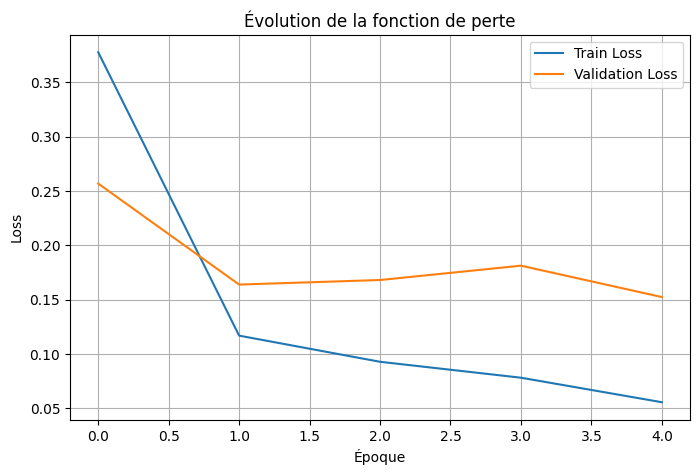

In [21]:

import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.grid(True)
plt.show()

# # Courbes d'accuracy
# plt.figure(figsize=(8, 5))
# plt.plot(history.history["accuracy"], label="Train Accuracy")
# plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
# plt.xlabel("Époque")
# plt.ylabel("Accuracy")
# plt.title("Évolution de l'accuracy")
# plt.legend()
# plt.grid(True)
# plt.show()


In [ ]:


from sklearn.metrics import f1_score, roc_auc_score


print(X_test.shape)

probabilities = model.predict(X_test, verbose=0).ravel()

y_pred = (probabilities >= 0.5).astype(int)

print("F1-score:", f1_score(y_test, y_pred))

scores = model.evaluate(X_test, y_test, return_dict = True)

print(scores)

roc_auc_score_ = roc_auc_score(y_test, y_pred)
print("roc_auc_score: ", roc_auc_score_)


(624, 180, 180, 3)
F1-score: 0.8629671574178935
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accuracy: 0.8061 - auc: 0.9080 - loss: 0.7318 - precision: 0.7728 - recall: 0.9769
{'accuracy': 0.8060897588729858, 'auc': 0.9080045223236084, 'loss': 0.7317908406257629, 'precision': 0.772819459438324, 'recall': 0.9769230484962463}


np.float64(0.7491452991452991)

In [23]:

# one image
image = X_test[0]

true_label = y_test[0]

image_batch = np.expand_dims(image, axis=0)

probabilities = model.predict(image_batch)

# Convert probabilities into classes
predicted_class = "PNEUMONIA" if probabilities[0][0] <= 0.5 else "NORMAL"
y_pred = 1 if probabilities[0][0] <= 0.5 else 0


print("true label: ", true_label)
print("Probabilité prédite :", probabilities[0][0])
print("prédicted_label: ", y_pred)
print("Classe prédite :", predicted_class)

print("y_pred: ", y_pred)
    
f1 = f1_score([true_label], [y_pred], zero_division=0)

print("F1-score :", f1)




1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
true label:  0.0
Probabilité prédite : 0.949744
prédicted_label:  0
Classe prédite : NORMAL
y_pred:  0
F1-score : 0.0


# Automize

In [ ]:
import kagglehub
from pathlib import Path
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
path = Path(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [3]:
train_directory =  path / "chest_xray" / "chest_xray" / "train"

val_directory =  path / "chest_xray" / "chest_xray" / "val"

test_directory =  path / "chest_xray" / "chest_xray" / "test"

In [ ]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_directory,
    labels="inferred",
    label_mode = 'binary', # should be like loss in model
    color_mode="rgb",
    batch_size=32,
    image_size=(180, 180),
    shuffle=True,
    seed = 42, # like random_state
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_directory,
    labels="inferred",
    label_mode = 'binary', # should be like loss in model
    color_mode="rgb",
    batch_size=32,
    image_size=(180, 180),
    shuffle=True,
    seed = 42, # like random_state
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    train_directory,
    labels="inferred",
    label_mode = 'binary', # should be like loss in model
    color_mode="rgb",
    batch_size=32,
    image_size=(180, 180),
    shuffle=True,
    seed = 42, # like random_state
)

Found 5216 files belonging to 2 classes.


In [ ]:
# normalization_layer = tf.keras.layers.Rescaling(1./255)

# train_ds = train_ds.map(
#     lambda images, labels: (
#         normalization_layer(images),
#         labels
#     )
# )

# val_ds = val_ds.map(
#     lambda images, labels: (
#         normalization_layer(images),
#         labels
#     )
# )

# test_ds = test_ds.map(
#     lambda images, labels: (    
#         normalization_layer(images),
#         labels
#     )
# )


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [ ]:

 
def class_weight():
    
    classes = np.unique(y_train)


    computed_class_weight = compute_class_weight(class_weight="balanced", classes=classes, y = y_train)

    class_weights = dict(zip(classes, computed_class_weight))

    return class_weights

computed_class_weight = class_weight()

In [ ]:



model = keras.Sequential([
    # Input images: height, width, RGB channels
    keras.Input(shape=(180, 180, 3)),
    layers.Resizing(180, 180),  # new layer, test it
    layers.Rescaling(1./255), # new layer, test it
     
    # Feature extraction
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Binary output: NORMAL or PNEUMONIA
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]
)

# model.summary()


In [ ]:
import numpy as np
import time 

early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)



history = model.fit(
    train_ds,
    epochs=5,
    batch_size=32,
    class_weight = class_weights,
    validation_data=val_ds,
    callbacks = [early_stopping]
)


<!-- إلا كنتي كتقصد بـ pipeline استعمال tf.data مع cache(), prefetch() لتحسين سرعة التدريب، تقدر تزيد هاد التحسينات قبل model.fit(). -->